# 09 — SegFormer-60 on six classes

Shrub & scrub, flooded vegetation and snow & ice score near zero, and validation holds
0.42%, 0.08% and 324 pixels of them — they cannot be measured there, yet each carries one
ninth of the mean. So: what does the model do when asked only about the six that can be?

Labels 7, 8 and 9 become **0, unlabelled** — the same treatment as a pixel no satellite
saw. The network has seven output channels; the six class ids are untouched, so every
number lines up with the "6 main" column of the nine-class runs.

Dropping rather than merging: folding shrub into grass would push a class the labels
disagree about into the weakest of the six.

The tiles are not rebuilt — the remap happens as each tile loads. A tile left under 10%
labelled is dropped, and the cell below reports how many and from where.

Recipe is notebook 05's, unchanged. Weights go to `weights/sixclass/`, so the prototype
cannot pick a six-class model as the one it serves.

In [1]:
import sys, pathlib, json, re, time, hashlib


def find_root(start=None):
    here = pathlib.Path(start or pathlib.Path.cwd()).resolve()
    for folder in [here, *here.parents]:
        if (folder / "config.py").exists():
            return folder
    raise SystemExit("config.py not found - open this notebook inside the project")


ROOT = find_root()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from tqdm import tqdm

import config
from training.model import build_model, count_parameters


def progress(iterable=None, **kw):
    return tqdm(iterable, file=sys.stdout, ncols=110, **kw)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORKERS = 4 if sys.platform != "win32" else 0
if sys.platform != "win32":
    torch.multiprocessing.set_sharing_strategy("file_system")

print("root:   ", ROOT)
print("torch   ", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "- NO GPU, this will crawl")
print("workers:", WORKERS)

root:    /home/jovyan/vault/exam/ECHOSCAPE
torch    2.9.1+cu128 | device: cuda (NVIDIA RTX A6000)
workers: 4


## Settings

In [2]:
NAME    = "segformer60_6cls"
MODEL   = "segformer"
EPOCHS  = 60               # notebook 05's length, so this compares with segformer60
BATCH   = 16
LR      = 3e-4
WARMUP  = 2
EMA_DECAY  = 0.999
CLIP       = 1.0
WEIGHT_CAP = 20.0
SEED       = 0
RESUME     = True          # re-run this notebook after a crash and it continues

KEEP = 6                   # classes 1..6 are kept; anything above becomes 0, unlabelled
NUM  = KEEP + 1            # network output channels, including 0
CLASSES = {i: config.CLASSES[i] for i in range(NUM)}
MIN_LABELLED = config.MIN_LABELLED_FRACTION * config.TILE_PX * config.TILE_PX

TILES   = config.TILES
OUT     = config.OUTPUTS / "sixclass"
WEIGHTS = config.WEIGHTS / "sixclass"      # kept out of weights/ so app/pipeline.py
OUT.mkdir(parents=True, exist_ok=True)     # cannot pick this as the model to serve
WEIGHTS.mkdir(parents=True, exist_ok=True)
RECIPE = "sixclass-60-epochs-ema"

print("keeping:", ", ".join(f"{i} {CLASSES[i]}" for i in range(1, NUM)))
print("dropping:", ", ".join(f"{i} {config.CLASSES[i]}" for i in range(NUM, config.NUM_CLASSES)))
print("results ->", OUT)
print("weights ->", WEIGHTS)

keeping: 1 water, 2 built-up, 3 trees, 4 cropland, 5 grass, 6 bare
dropping: 7 shrub & scrub, 8 flooded vegetation, 9 snow & ice
results -> /home/jovyan/vault/exam/ECHOSCAPE/outputs/sixclass
weights -> /home/jovyan/vault/exam/ECHOSCAPE/weights/sixclass


## Which tiles survive the drop

A tile of pure glacier or pure swamp has nothing left to learn from once those labels
become unlabelled. This applies `build_dataset.py`'s own rule — keep a tile only if at
least 10% of its pixels carry a label — and reports what it costs, by region.

The scan reads every tile once and caches the answer.

In [3]:
TILE_NAME = re.compile(r"^(?P<aoi>.+)_(?P<month>\d{4}-\d{2})_r(?P<row>\d+)_c(?P<col>\d+)$")


def parts(path):
    found = TILE_NAME.match(path.stem)
    if not found:
        raise ValueError(f"unexpected tile name: {path.name}")
    return found


def remap(y):
    """Labels 7, 8, 9 -> 0. The six kept classes already hold ids 1..6."""
    return np.where(y > KEEP, 0, y)


def survey():
    """Per split: the tiles that keep >=10% labelled pixels after the remap."""
    splits = ("train", "val", "test")
    found = {s: sorted((TILES / s).glob("*.npz")) for s in splits}
    signature = hashlib.sha1(
        "|".join(f"{s}:{len(found[s])}" for s in splits).encode()).hexdigest()[:12]
    cache = OUT / f"tiles_{signature}.json"
    if cache.exists():
        saved = json.loads(cache.read_text())
        print("reusing the cached scan")
        return ({s: [TILES / s / n for n in saved["keep"][s]] for s in splits},
                saved["dropped"], np.array(saved["counts"], dtype=np.int64))

    keep, dropped = {s: [] for s in splits}, {}
    counts = np.zeros(NUM, dtype=np.int64)
    for split in splits:
        for f in progress(found[split], desc=f"scanning {split}", unit="tile"):
            with np.load(f) as data:
                y = remap(data["y"])
            labelled = int((y > 0).sum())
            if labelled < MIN_LABELLED:
                aoi = parts(f).group("aoi")
                dropped[aoi] = dropped.get(aoi, 0) + 1
                continue
            keep[split].append(f)
            if split == "train":
                counts += np.bincount(y.ravel(), minlength=NUM)

    cache.write_text(json.dumps({
        "keep": {s: [f.name for f in keep[s]] for s in splits},
        "dropped": dropped, "counts": counts.tolist()}, indent=2))
    return keep, dropped, counts


keep, dropped, train_counts = survey()

splits = ("train", "val", "test")
before = {s: len(sorted((TILES / s).glob("*.npz"))) for s in splits}
print()
for s in splits:
    lost = before[s] - len(keep[s])
    print(f"{s:<6}{len(keep[s]):>6,} tiles kept of {before[s]:>6,}"
          f"   ({lost:,} dropped, {100 * lost / max(before[s], 1):.1f}%)")

if dropped:
    print("\nwhere the dropped tiles came from:")
    for aoi, n in sorted(dropped.items(), key=lambda kv: -kv[1]):
        print(f"   {aoi:<16}{n:>5} tiles")
    print("\nThose are the regions whose ground is mostly a class this model no longer has.")
    print("Six of them were downloaded on 9 November specifically FOR those classes, so a")
    print("six-class model gets little from that work - worth saying in the report.")

labelled = train_counts[1:].sum()
print(f"\ntraining pixels after the drop: {labelled:,}")
for i in range(1, NUM):
    print(f"   {CLASSES[i]:<20}{train_counts[i]:>14,}{100 * train_counts[i] / labelled:>8.2f}%")
print(f"\nimbalance, commonest to rarest: "
      f"{train_counts[1:].max() / max(train_counts[1:].min(), 1):.1f}x")

reusing the cached scan

train  6,228 tiles kept of  7,164   (936 dropped, 13.1%)
val    1,800 tiles kept of  1,800   (0 dropped, 0.0%)
test   2,100 tiles kept of  2,100   (0 dropped, 0.0%)

where the dropped tiles came from:
   kalahari          300 tiles
   vatnajokull       300 tiles
   everglades        204 tiles
   baltoro           132 tiles

Those are the regions whose ground is mostly a class this model no longer has.
Six of them were downloaded on 9 November specifically FOR those classes, so a
six-class model gets little from that work - worth saying in the report.

training pixels after the drop: 79,825,181
   water                    8,179,644   10.25%
   built-up                15,466,692   19.38%
   trees                   12,455,597   15.60%
   cropland                18,989,892   23.79%
   grass                    4,799,136    6.01%
   bare                    19,934,220   24.97%

imbalance, commonest to rarest: 4.2x


## The remap, checked

Three assertions instead of the overfit test. The training code below is notebook 05's,
already proven on this data; the one new thing is the remap, so that is what gets checked:
no label above 6 survives, no kept tile is empty, and the kept ids are untouched.

In [4]:
sample = keep["train"][::max(len(keep["train"]) // 40, 1)][:40]
highest, emptiest, changed = 0, 1.0, 0
for f in sample:
    with np.load(f) as data:
        raw = data["y"]
    y = remap(raw)
    highest = max(highest, int(y.max()))
    emptiest = min(emptiest, float((y > 0).mean()))
    changed += int(((raw != y) & (raw <= KEEP)).sum())

assert highest <= KEEP, f"a label of {highest} survived the remap"
assert emptiest >= config.MIN_LABELLED_FRACTION, f"a kept tile is only {emptiest:.1%} labelled"
assert changed == 0, f"{changed} pixels of the six kept classes were altered"
print(f"checked {len(sample)} tiles: max label {highest}, emptiest kept tile "
      f"{100 * emptiest:.1f}% labelled, kept classes untouched")

checked 40 tiles: max label 6, emptiest kept tile 14.8% labelled, kept classes untouched


## Data, loss, scoring

Identical to the nine-class runs apart from the remap and the seven output channels.

In [5]:
class Tiles(Dataset):
    """Tiles with the three dropped classes turned into unlabelled."""

    def __init__(self, files, augment=False, seed=0):
        self.files = list(files)
        if not self.files:
            raise SystemExit("no tiles left after the drop")
        self.augment = augment
        self.seed = seed
        self._rng = None

    def __len__(self):
        return len(self.files)

    def rng(self):
        if self._rng is None:
            self._rng = np.random.default_rng(torch.initial_seed() % (2 ** 32) + self.seed)
        return self._rng

    def __getitem__(self, index):
        with np.load(self.files[index]) as data:
            x = data["x"].astype("float32")
            y = remap(data["y"]).astype("int64")

        if self.augment:
            rng = self.rng()
            if rng.random() < 0.5:
                x, y = x[:, :, ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                x, y = x[:, ::-1, :], y[::-1, :]
            turns = int(rng.integers(4))
            if turns:
                x = np.rot90(x, turns, axes=(1, 2))
                y = np.rot90(y, turns)
            x = x * rng.normal(1.0, 0.05, x.shape).astype("float32")
            x = x + rng.normal(0.0, 0.02)
            x = np.clip(x, 0.0, 1.0)

        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y)))


def class_weights(counts, cap=WEIGHT_CAP):
    """Capped inverse frequency, averaging 1 - the nine-class runs' maths, over six."""
    counts = np.asarray(counts, dtype="float64")
    present = counts[1:] > 0
    inverse = np.zeros(NUM - 1, dtype="float64")
    inverse[present] = counts[1:][present].sum() / counts[1:][present]
    floor = inverse[present].min()
    squashed = int((inverse[present] > floor * cap).sum())
    capped = np.minimum(inverse[present], floor * cap)
    inverse[present] = capped / capped.mean()
    weights = np.zeros(NUM, dtype="float32")
    weights[1:] = inverse
    if squashed:
        print(f"   capped {squashed} weight(s) at {cap:.0f}x")
    print("   loss weights: " + "  ".join(
        f"{CLASSES[i][:8]} {weights[i]:.2f}" for i in range(1, NUM)))
    return torch.tensor(weights, device=DEVICE)


def metric_variants(matrix):
    matrix = np.asarray(matrix)
    ious, support = {}, {}
    for c in range(1, matrix.shape[0]):
        seen = int(matrix[c, :].sum())
        if seen == 0:
            continue
        hit = matrix[c, c]
        union = matrix[c, :].sum() + matrix[:, c].sum() - hit
        ious[c] = float(hit / union) if union else 0.0
        support[c] = seen
    total = sum(support.values()) or 1
    return {
        "miou": float(np.mean(list(ious.values()))) if ious else 0.0,
        "miou_weighted_by_support": float(sum(ious[c] * support[c] for c in ious) / total),
        "accuracy": float(np.trace(matrix) / max(matrix.sum(), 1)),
        "per_class": {CLASSES[c]: ious[c] for c in sorted(ious)},
        "support": {CLASSES[c]: support[c] for c in sorted(support)},
    }


@torch.no_grad()
def confuse(net, loader, tta=False, desc=None):
    net.eval()
    matrix = np.zeros((NUM, NUM), dtype="int64")
    stream = progress(loader, desc=desc, unit="batch") if desc else loader
    for x, y in stream:
        x, y = x.to(DEVICE), y.to(DEVICE)
        probs = net(x).softmax(1)
        if tta:
            for dims in ([2], [3], [2, 3]):
                probs = probs + torch.flip(net(torch.flip(x, dims)), dims).softmax(1)
        predicted = probs.argmax(1)
        kept = y > 0
        if kept.any():
            np.add.at(matrix, (y[kept].cpu().numpy(), predicted[kept].cpu().numpy()), 1)
    return matrix


@torch.no_grad()
def year_confuse(net, files, tta=False, desc="year"):
    """One prediction per place, from all its months averaged before the argmax."""
    net.eval()
    places = {}
    for f in files:
        found = parts(f)
        places.setdefault((found["aoi"], found["row"], found["col"]), []).append(f)

    matrix = np.zeros((NUM, NUM), dtype="int64")
    for _, group in progress(sorted(places.items()), desc=desc, unit="place"):
        xs, ys = [], []
        for f in group:
            with np.load(f) as data:
                xs.append(data["x"].astype("float32"))
                ys.append(remap(data["y"]).astype("int64"))
        x = torch.from_numpy(np.stack(xs)).to(DEVICE)
        probs = net(x).softmax(1)
        if tta:
            for dims in ([2], [3], [2, 3]):
                probs = probs + torch.flip(net(torch.flip(x, dims)), dims).softmax(1)
        predicted = probs.mean(0).argmax(0).cpu().numpy()
        y = max(ys, key=lambda a: int((a > 0).sum()))
        kept = y > 0
        np.add.at(matrix, (y[kept], predicted[kept]), 1)
    return matrix


def show(title, scored):
    print(f"\n{title}")
    for name, value in scored["per_class"].items():
        print(f"   {name:<20}{100 * value:>7.1f}%{scored['support'][name]:>14,} px")

## Train

One progress bar per epoch. Re-run this cell after a crash and it continues from the last
checkpoint.

In [6]:
def save_atomically(payload, path):
    tmp = path.with_suffix(".tmp")
    torch.save(payload, tmp)
    tmp.replace(path)


def train(workers=None):
    workers = WORKERS if workers is None else workers
    torch.manual_seed(SEED)
    np.random.seed(SEED)

    train_loader = DataLoader(Tiles(keep["train"], augment=True, seed=SEED),
                              batch_size=BATCH, shuffle=True, num_workers=workers)
    val_loader = DataLoader(Tiles(keep["val"]), batch_size=BATCH, num_workers=workers)

    net = build_model(MODEL, in_channels=3, classes=NUM).to(DEVICE)
    print(f"{MODEL}: {count_parameters(net):,} parameters, {NUM} output channels")
    print(f"   train {len(keep['train']):,} tiles   val {len(keep['val']):,} tiles")

    criterion = nn.CrossEntropyLoss(weight=class_weights(train_counts), ignore_index=0)
    optimiser = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
    schedule = torch.optim.lr_scheduler.SequentialLR(optimiser, [
        torch.optim.lr_scheduler.LinearLR(optimiser, start_factor=0.1, total_iters=WARMUP),
        torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, EPOCHS - WARMUP, eta_min=LR * 0.01),
    ], milestones=[WARMUP])
    ema = AveragedModel(net, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)

    last_path, best_path = WEIGHTS / f"{NAME}_last.pt", WEIGHTS / f"{NAME}_best.pt"
    best, best_epoch, history, first = -1.0, 0, [], 1

    if RESUME and last_path.exists():
        saved = torch.load(last_path, map_location=DEVICE, weights_only=False)
        if saved.get("recipe") != RECIPE:
            raise SystemExit(f"{last_path.name} is from another recipe - move it aside")
        net.load_state_dict(saved["state"])
        ema.load_state_dict(saved["ema"])
        optimiser.load_state_dict(saved["optimiser"])
        schedule.load_state_dict(saved["schedule"])
        history, best, first = saved["history"], saved["best"], saved["epoch"] + 1
        best_epoch = max(history, key=lambda h: h["val_miou"])["epoch"]
        print(f"resuming at epoch {first} (best so far {100 * best:.1f}% at epoch {best_epoch})")

    started = time.time()
    for epoch in range(first, EPOCHS + 1):
        net.train()
        running = 0.0
        bar = progress(total=len(train_loader), desc=f"epoch {epoch:>3}/{EPOCHS}", unit="batch")
        for step, (x, y) in enumerate(train_loader, start=1):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimiser.zero_grad(set_to_none=True)
            loss = criterion(net(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), CLIP)
            optimiser.step()
            ema.update_parameters(net)
            running += float(loss.item())
            bar.set_postfix_str(f"loss {running / step:.4f}", refresh=False)
            bar.update(1)
        schedule.step()
        mean_loss = running / max(len(train_loader), 1)

        bar.set_postfix_str(f"loss {mean_loss:.4f} | validating...")
        scored = metric_variants(confuse(ema.module, val_loader))
        history.append({"epoch": epoch, "loss": mean_loss, "val_miou": scored["miou"],
                        "val_acc": scored["accuracy"]})

        marker = ""
        if scored["miou"] > best:
            best, best_epoch, marker = scored["miou"], epoch, "  <- best, saved"
            save_atomically({"state": ema.module.state_dict(), "model": MODEL,
                             "kwargs": net.kwargs, "epoch": epoch, "classes": NUM,
                             "val_miou": best, "recipe": RECIPE}, best_path)
        save_atomically({"state": net.state_dict(), "ema": ema.state_dict(),
                         "optimiser": optimiser.state_dict(), "schedule": schedule.state_dict(),
                         "epoch": epoch, "best": best, "history": history, "model": MODEL,
                         "kwargs": net.kwargs, "recipe": RECIPE}, last_path)

        bar.set_postfix_str(f"loss {mean_loss:.4f} | val mIoU {100 * scored['miou']:.1f}% | "
                            f"acc {100 * scored['accuracy']:.1f}%{marker}")
        bar.close()

    print(f"\nfinished in {(time.time() - started) / 60:.1f} min, best epoch {best_epoch}")
    return net, best_path, history


try:
    net, best_path, history = train()
except RuntimeError as problem:
    text, cause = "", problem
    for _ in range(10):
        text += " " + str(cause).lower()
        cause = cause.__cause__ or cause.__context__
        if cause is None:
            break
    if not ("shared memory" in text or "bus error" in text
            or ("worker" in text and "exited unexpectedly" in text)):
        raise
    print("\na loader worker was killed for want of shared memory - retrying with workers=0")
    net, best_path, history = train(workers=0)

segformer: 2,280,071 parameters, 7 output channels
   train 6,228 tiles   val 1,800 tiles
   loss weights: water 1.27  built-up 0.67  trees 0.83  cropland 0.55  grass 2.16  bare 0.52
epoch   1/60: 100%|█| 390/390 [00:12<00:00, 30.59batch/s, loss 1.4591 | val mIoU 3.9% | acc 16.8%  <- best, sa
epoch   2/60: 100%|█| 390/390 [00:09<00:00, 43.24batch/s, loss 1.0670 | val mIoU 6.7% | acc 20.5%  <- best, sa
epoch   3/60: 100%|█| 390/390 [00:09<00:00, 42.67batch/s, loss 0.8858 | val mIoU 8.2% | acc 22.4%  <- best, sa
epoch   4/60: 100%|█| 390/390 [00:09<00:00, 42.86batch/s, loss 0.7684 | val mIoU 27.8% | acc 45.3%  <- best, s
epoch   5/60: 100%|█| 390/390 [00:08<00:00, 44.48batch/s, loss 0.7096 | val mIoU 35.3% | acc 53.2%  <- best, s
epoch   6/60: 100%|█| 390/390 [00:09<00:00, 42.89batch/s, loss 0.6491 | val mIoU 45.1% | acc 60.7%  <- best, s
epoch   7/60: 100%|█| 390/390 [00:09<00:00, 42.66batch/s, loss 0.6198 | val mIoU 50.8% | acc 64.8%  <- best, s
epoch   8/60: 100%|█| 390/390 [00:09<00:

## Score

The best epoch's averaged weights, four ways, on validation and on test.

In [7]:
saved = torch.load(best_path, map_location=DEVICE, weights_only=False)
net.load_state_dict(saved["state"])
print(f"scoring the best epoch ({saved['epoch']}), not the last")

scores, confusion = {}, {}
for split in ("val", "test"):
    loader = DataLoader(Tiles(keep[split]), batch_size=BATCH, num_workers=WORKERS)
    confusion[split] = confuse(net, loader, desc=f"{split} plain   ")
    scores[split] = {
        "plain":    metric_variants(confusion[split]),
        "tta":      metric_variants(confuse(net, loader, tta=True, desc=f"{split} +TTA    ")),
        "year":     metric_variants(year_confuse(net, keep[split], desc=f"{split} +year   ")),
        "year_tta": metric_variants(year_confuse(net, keep[split], tta=True,
                                                 desc=f"{split} +year+TTA")),
    }

print(f"\n{'split':<7}{'variant':<10}{'mIoU (6)':>11}{'area-weighted':>15}{'accuracy':>11}")
for split in ("val", "test"):
    for variant, scored in scores[split].items():
        print(f"{split:<7}{variant:<10}{100 * scored['miou']:>10.1f}%"
              f"{100 * scored['miou_weighted_by_support']:>14.1f}%"
              f"{100 * scored['accuracy']:>10.1f}%")

show("VALIDATION, per class (plain)", scores["val"]["plain"])
show("TEST, per class (plain)", scores["test"]["plain"])

result = {"model": NAME, "architecture": MODEL, "classes": NUM, "dropped":
          [config.CLASSES[i] for i in range(NUM, config.NUM_CLASSES)],
          "parameters": count_parameters(net), "recipe": RECIPE,
          "best_epoch": saved["epoch"], "epochs": EPOCHS,
          "tiles": {s: len(keep[s]) for s in ("train", "val", "test")},
          "dropped_tiles": dropped, "train_counts": train_counts.tolist(),
          "scores": scores, "history": history,
          "confusion": {s: confusion[s].tolist() for s in ("val", "test")}}
(OUT / f"{NAME}_result.json").write_text(json.dumps(result, indent=2))
print(f"\nwritten to {OUT / f'{NAME}_result.json'}")

scoring the best epoch (45), not the last
test +year+TTA: 100%|████████████████████████████████████████████████████| 175/175 [00:04<00:00, 38.07place/s]

split  variant      mIoU (6)  area-weighted   accuracy
val    plain           75.4%          75.4%      85.3%
val    tta             75.4%          75.4%      85.2%
val    year            82.8%          82.6%      90.0%
val    year_tta        82.9%          82.7%      90.1%
test   plain           49.1%          56.5%      69.3%
test   tta             49.8%          57.1%      69.8%
test   year            52.4%          59.9%      72.2%
test   year_tta        52.3%          59.8%      72.1%

VALIDATION, per class (plain)
   water                  90.3%     4,168,440 px
   built-up               84.4%     4,184,028 px
   trees                  58.8%     5,075,052 px
   cropland               63.5%     4,702,548 px
   grass                  63.8%     3,373,332 px
   bare                   91.7%     4,919,256 px

TEST, per class (plain)
 

## Against the nine-class model

The comparison that matters: the same architecture, same recipe, same length — nine
classes against six. The nine-class figures are its "6 main" column, read from
`outputs/exp08/free.json` if that is there, and otherwise the values already on record.

In [8]:
# segformer60, nine classes, 6-main column - from this project's own runs
NINE = {("val", "plain"): 75.7, ("val", "tta"): 76.9, ("val", "year"): 82.6,
        ("val", "year_tta"): 84.4, ("test", "plain"): 47.3, ("test", "tta"): 48.0,
        ("test", "year"): 48.9, ("test", "year_tta"): 49.8}

free = config.OUTPUTS / "exp08" / "free.json"
if free.exists():
    label = {"plain": "plain", "tta": "tta", "year": "year", "year+tta": "year_tta"}
    for row in json.loads(free.read_text())["rows"]:
        if row["run"] == "segformer60" and row["variant"] in label:
            NINE[(row["split"], label[row["variant"]])] = 100 * row["miou_6_main"]
    print("nine-class figures read from outputs/exp08/free.json")

print(f"\n{'split':<7}{'variant':<10}{'9-class (6 main)':>18}{'6-class':>10}{'change':>9}")
for split in ("val", "test"):
    for variant in ("plain", "tta", "year", "year_tta"):
        six = 100 * scores[split][variant]["miou"]
        nine = NINE.get((split, variant))
        # Built as strings first: formatting None with a width raises TypeError.
        shown = f"{nine:.1f}%" if nine is not None else "-"
        delta = f"{six - nine:+.1f}" if nine is not None else ""
        print(f"{split:<7}{variant:<10}{shown:>18}{six:>9.1f}%{delta:>9}")

print("\nA gain means the three near-empty classes were costing the other six - capacity,")
print("and pixels lost to wrong predictions. No gain means they were already harmless and")
print("the nine-class model gives the same six-class performance plus three more classes.")
print("Either way the validation-to-test gap is the number to report alongside it.")

nine-class figures read from outputs/exp08/free.json

split  variant     9-class (6 main)   6-class   change
val    plain                  75.7%     75.4%     -0.3
val    tta                    76.9%     75.4%     -1.5
val    year                   82.6%     82.8%     +0.2
val    year_tta               84.4%     82.9%     -1.5
test   plain                  47.3%     49.1%     +1.8
test   tta                    48.0%     49.8%     +1.8
test   year                   48.9%     52.4%     +3.5
test   year_tta               49.8%     52.3%     +2.5

A gain means the three near-empty classes were costing the other six - capacity,
and pixels lost to wrong predictions. No gain means they were already harmless and
the nine-class model gives the same six-class performance plus three more classes.
Either way the validation-to-test gap is the number to report alongside it.


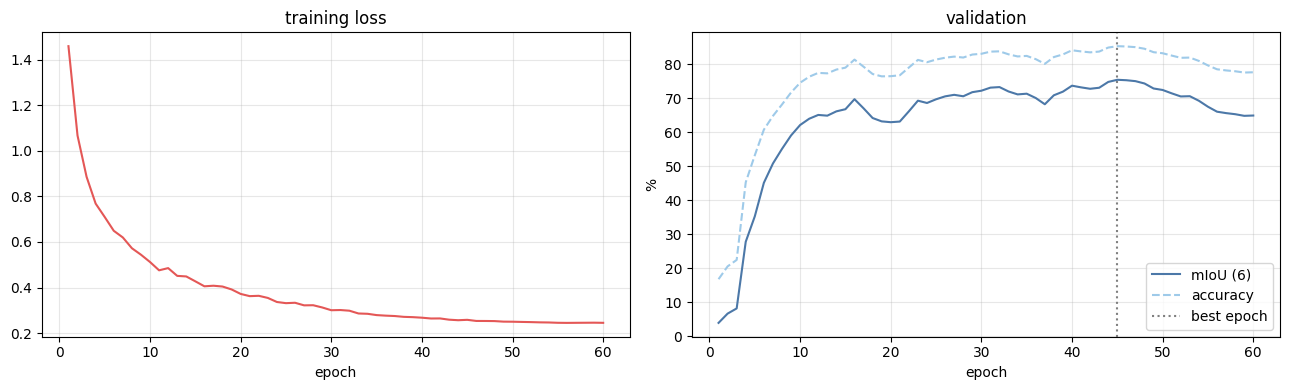

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
epochs = [h["epoch"] for h in history]
left.plot(epochs, [h["loss"] for h in history], color="#E45756")
left.set_title("training loss"); left.set_xlabel("epoch"); left.grid(alpha=0.3)
right.plot(epochs, [100 * h["val_miou"] for h in history], label="mIoU (6)", color="#4C78A8")
right.plot(epochs, [100 * h["val_acc"] for h in history], label="accuracy",
           color="#9ECAE9", linestyle="--")
right.axvline(saved["epoch"], color="grey", linestyle=":", label="best epoch")
right.set_title("validation"); right.set_xlabel("epoch"); right.set_ylabel("%")
right.legend(); right.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
lines = [f"## N. Six classes instead of nine - {time.strftime('%d %B %Y')}", "",
         f"`notebooks/09_sixclass.ipynb`. {MODEL} ({count_parameters(net):,} parameters), "
         f"{EPOCHS} epochs, notebook 05's recipe unchanged. Labels "
         + ", ".join(result["dropped"]) + " become unlabelled, so the network has "
         f"{NUM} output channels and those pixels leave both the loss and the score.", "",
         f"Tiles kept: train {len(keep['train']):,}, val {len(keep['val']):,}, "
         f"test {len(keep['test']):,} "
         f"(of {before['train']:,} / {before['val']:,} / {before['test']:,}; a tile with "
         f"under 10% of its pixels still labelled is dropped).", "",
         "| | 9-class, 6 main | 6-class | change |", "|---|---|---|---|"]
for split in ("val", "test"):
    for variant in ("plain", "year_tta"):
        six = 100 * scores[split][variant]["miou"]
        nine = NINE.get((split, variant))
        lines.append(f"| {split}, {variant.replace('_', '+')} | "
                     + (f"{nine:.1f}%" if nine is not None else "-") + f" | {six:.1f}% | "
                     + (f"{six - nine:+.1f}" if nine is not None else "-") + " |")
lines += ["", "Per-class validation IoU (plain): "
          + ", ".join(f"{k} {100 * v:.1f}%" for k, v in scores["val"]["plain"]["per_class"].items()),
          "", "Per-class test IoU (plain): "
          + ", ".join(f"{k} {100 * v:.1f}%" for k, v in scores["test"]["plain"]["per_class"].items())]
report = "\n".join(lines)
(OUT / "report.md").write_text(report, encoding="utf-8")
print(report)

## N. Six classes instead of nine - 09 November 2026

`notebooks/09_sixclass.ipynb`. segformer (2,280,071 parameters), 60 epochs, notebook 05's recipe unchanged. Labels shrub & scrub, flooded vegetation, snow & ice become unlabelled, so the network has 7 output channels and those pixels leave both the loss and the score.

Tiles kept: train 6,228, val 1,800, test 2,100 (of 7,164 / 1,800 / 2,100; a tile with under 10% of its pixels still labelled is dropped).

| | 9-class, 6 main | 6-class | change |
|---|---|---|---|
| val, plain | 75.7% | 75.4% | -0.3 |
| val, year+tta | 84.4% | 82.9% | -1.5 |
| test, plain | 47.3% | 49.1% | +1.8 |
| test, year+tta | 49.8% | 52.3% | +2.5 |

Per-class validation IoU (plain): water 90.3%, built-up 84.4%, trees 58.8%, cropland 63.5%, grass 63.8%, bare 91.7%

Per-class test IoU (plain): water 58.1%, built-up 70.6%, trees 64.8%, cropland 39.5%, grass 12.0%, bare 49.3%


## What this does not change

The prototype, the monthly-change product and the decision in `changes.md` Phase 3 §11
all stay nine-class. This measures what that decision costs; it does not reverse it.